# **Climate Resilience in Florence**

### Imports

In [1]:
import sys
import os
parent_dir = os.path.abspath("../../libraries/climate_resilience")
sys.path.insert(0, parent_dir)

import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
import climate_resilience as cr

### User inputs

In [3]:
api_key = 'ffd7d363-d7bd-4314-acc7-e88827069c50'

latitude = 43.7697
longitude = 11.2558

### Coordinate check

In [4]:
city, country = cr.coordinate_check(latitude, longitude)
print("{}, {}".format(city, country))

Loading formatted geocoded file...
Florence, IT


In [5]:
cr.get_map(latitude, longitude, city, country)

### Data request

In [6]:
experiment_option = "Historical + RCP 4.5"
variable_option = "Maximum Temperature"
model_name = 'IRNET'

In [7]:
model_data = cr.request_data(api_key, model_name, experiment_option, variable_option, latitude, longitude, city)

2025-07-30 22:35:38,491 INFO [2024-09-26T00:00:00] Watch our [Forum](https://forum.ecmwf.int/) for Announcements, news and other discussed topics.
2025-07-30 22:35:38,667 INFO [2024-09-26T00:00:00] Watch our [Forum](https://forum.ecmwf.int/) for Announcements, news and other discussed topics.
2025-07-30 22:35:42,501 INFO Request ID is 9f272b8a-df50-47ed-9840-b7da68bb25b9
2025-07-30 22:35:42,574 INFO status has been updated to accepted
2025-07-30 22:35:51,261 INFO status has been updated to running
2025-07-30 22:35:56,371 INFO status has been updated to successful


2a99ed52dd64827fe9731e33c6dcf74a.zip:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Dataset 'IRNET_orography' downloaded and added to dictionary
Data for 'IRNET_orography':


,rlon,rlat,rotated_pole,lon,lat,orog
0,-28.375,-23.375,b'',-10.063880,21.987829,265.612701
1,-28.375,-23.265,b'',-10.110996,22.088787,269.615082
2,-28.375,-23.155,b'',-10.158180,22.189732,274.739166
3,-28.375,-23.045,b'',-10.205431,22.290664,281.163361
4,-28.375,-22.935,b'',-10.252751,22.391581,289.754486


2025-07-30 22:36:05,081 INFO [2024-09-26T00:00:00] Watch our [Forum](https://forum.ecmwf.int/) for Announcements, news and other discussed topics.





Processing city: Florence (Lat: 43.7697, Lon: 11.2558)
  Closest Point in IRNET_orography:
  Latitude: 43.757510, Longitude: 11.193669
  rlat: -6.765000, rlon: -4.945000
  Area area: [-6.765, -4.945, -6.765, -4.945]
coordinates:  {'area': [-6.765, -4.945, -6.765, -4.945]}
IRNET


2025-07-30 22:36:05,202 INFO [2024-09-26T00:00:00] Watch our [Forum](https://forum.ecmwf.int/) for Announcements, news and other discussed topics.
2025-07-30 22:36:08,961 INFO Request ID is c7a2104c-b1b2-4634-add2-328f660665a2
2025-07-30 22:36:09,048 INFO status has been updated to accepted
2025-07-30 22:36:17,690 INFO status has been updated to running
2025-07-30 22:36:22,848 INFO status has been updated to successful


2c35a538f5515a12d301fa7d00f48f7c.zip:   0%|          | 0.00/11.0M [00:00<?, ?B/s]

  0%|          | 0/31 [00:00<?, ?it/s]

Dataset 'IRNET' downloaded and added to dictionary
{'IRNET':                       time  bnds   rlat   rlon rotated_pole  time_bnds  \
0      1950-01-01 12:00:00     0 -6.765 -4.945          b'' 1950-01-01   
1      1950-01-01 12:00:00     1 -6.765 -4.945          b'' 1950-01-02   
2      1950-01-02 12:00:00     0 -6.765 -4.945          b'' 1950-01-02   
3      1950-01-02 12:00:00     1 -6.765 -4.945          b'' 1950-01-03   
4      1950-01-03 12:00:00     0 -6.765 -4.945          b'' 1950-01-03   
...                    ...   ...    ...    ...          ...        ...   
110299 2100-12-29 12:00:00     1 -6.765 -4.945          b'' 2100-12-30   
110300 2100-12-30 12:00:00     0 -6.765 -4.945          b'' 2100-12-30   
110301 2100-12-30 12:00:00     1 -6.765 -4.945          b'' 2100-12-31   
110302 2100-12-31 12:00:00     0 -6.765 -4.945          b'' 2100-12-31   
110303 2100-12-31 12:00:00     1 -6.765 -4.945          b'' 2101-01-01   

            tasmax        lon       lat  height  


### Data processing

In [8]:
window_length=40
shift=10

In [9]:
dfs_processed, windows = cr.processed_dataframe(model_data, window_length=window_length, shift=shift)

Dataset: IRNET, Window: 1950-1989
Dataset: IRNET, Window: 1960-1999
Dataset: IRNET, Window: 1970-2009
Dataset: IRNET, Window: 1980-2019
Dataset: IRNET, Window: 1990-2029
Dataset: IRNET, Window: 2000-2039
Dataset: IRNET, Window: 2010-2049
Dataset: IRNET, Window: 2020-2059
Dataset: IRNET, Window: 2030-2069
Dataset: IRNET, Window: 2040-2079
Dataset: IRNET, Window: 2050-2089
Dataset: IRNET, Window: 2060-2099


### Calculating result values

In [10]:
T_r = 50
method = "MLM"

In [11]:
results = cr.ev1_param(dfs_processed, T_r, method)

### Plot results

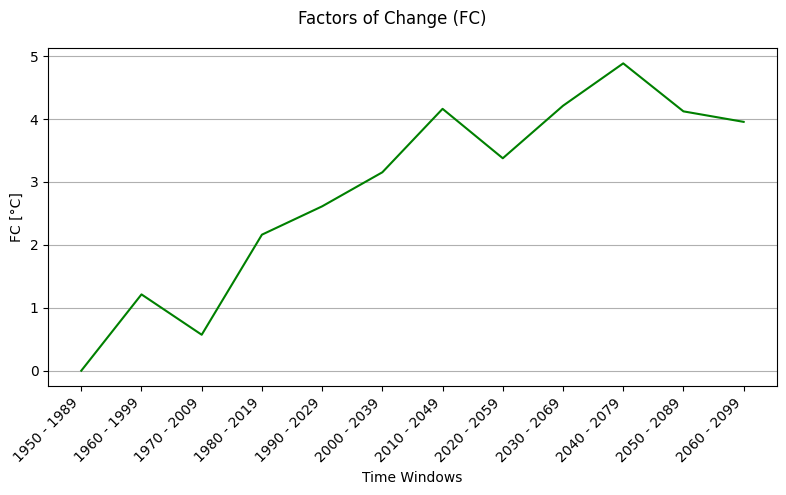

In [12]:
value = 'Factors of Change of Characteristic value'

fig, dataframe = cr.model_output(results, value, dfs_processed, T_r)

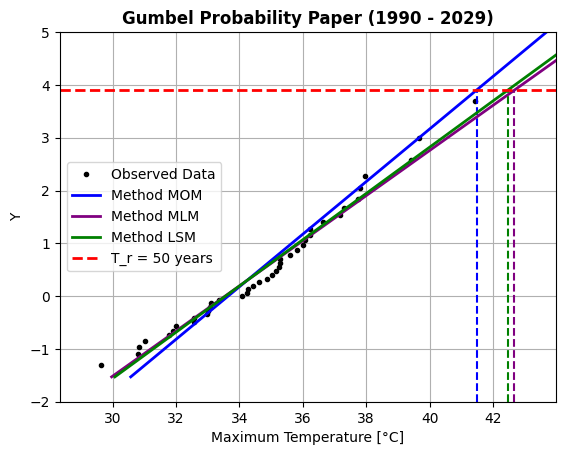

In [13]:
value = 'Gumbel Probability Paper'

window = windows[4]

fig = cr.model_output(results, value, dfs_processed, T_r, window)